# ANN Hackathon — Template + Worked Sample on **Real-Time Data**

**Sample problem: Live PM2.5 forecasting** — a neural network reads the last 24 hours of air quality and weather for a city and forecasts **PM2.5 for each of the next 6 hours**. It also gives the matching **Indian AQI category** (Good … Severe).

**Why this notebook exists.** Students are asked to *take a real-time dataset and solve a problem with ANN concepts*. This notebook is a complete worked example of doing exactly that, from the first API call to a live forecast that checks itself. Copy its structure for your own data source.

It keeps the 12-step template from the waveform sample, with three changes:

* **Real data, pulled live** from the free [Open-Meteo](https://open-meteo.com) APIs (no key, no sign-up). The notebook downloads the last year of hourly data every time it runs, so the newest hours are always included.
* **A real forecasting problem**: time-ordered splits, a persistence baseline, multi-step output, and a skill score.
* **Step 13 — Live forecast.** It fetches the latest hours, forecasts the next 6, compares that with the official CAMS forecast, and logs the forecast. When you run it again later, it scores the earlier forecasts against what actually happened.

| Step | What you do | Concept (syllabus link) |
|---|---|---|
| 0 | Setup & config | Reproducibility (random seeds) |
| 1 | Frame the problem | **Prediction** → time-delay input (TDNN) (Unit 5) |
| 2 | Load the data **live from an API** (with offline cache) | Selection of data, input range (Unit 5) |
| 3 | Explore the data | Daily cycle, seasonality, skewed distribution |
| 4 | Preprocess | Log transform, normalization (training statistics only), time-delay windows |
| 5 | Split train / val / test **by time** | 70 / 15 / 15, with a gap so no hour leaks (Unit 5) |
| 6 | Baselines | Persistence ("tomorrow = today") and linear regression |
| 7 | Build the network | TDNN / MLP (or LSTM); linear output for fitting (Units 1–3, 5) |
| 8 | Train with early stopping | Backpropagation, validation curve, overfitting (Units 3, 5) |
| 9 | Evaluate on the test set | RMSE / MAE, regression m, c, R, skill score, AQI confusion matrix (Unit 5) |
| 10 | Error analysis | Error vs horizon, hour of day and pollution level |
| 11 | Hard path: generalise to a new city | Extrapolation trap → scale-free inputs fix it (Unit 5) |
| 12 | Sensitivity + slide summary | ∂output/∂input per feature and per lag (Unit 5) |
| 13 | **Live forecast + self-scoring log** | Deploying the network on data that arrives in real time |

**Runs on:** Google Colab (CPU is enough) in about 2–4 minutes. **Needs internet** for the live download. If the API is down, it falls back to the last cached CSV.

> **About the data:** Open-Meteo's air-quality values come from the **CAMS** atmospheric model (Copernicus), combined with satellite and ground observations. They are not readings from one ground station. They are hourly, cover the whole world and are always available, which makes them good for a template. If you want real station readings, see the 🔁 note in Step 2.

## Step 0 — Setup and config
Fix the random seeds so you get the same result on every run. Put every number you might tune in one `CONFIG` dictionary. The city coordinates are in `CONFIG` too, so you can point the notebook at your own city.

In [1]:
import os, glob, time, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)

# 🔁 CHANGE FOR YOUR THEME / CITY
CONFIG = dict(
    theme="Live PM2.5 forecasting (real-time sample)",
    tier="Hard path",                       # Foundation / Advanced / Hard path
    city=dict(name="Bengaluru", lat=12.97, lon=77.59),
    new_city=dict(name="Delhi", lat=28.61, lon=77.21),   # Hard path: a city the model never trains on
    timezone="Asia/Kolkata",
    history_days=365,                       # how much past data to download
    window=24,                              # hours of history the network sees (time-delay taps)
    horizon=6,                              # forecast 1..6 hours ahead
    model="mlp",                            # "mlp" (TDNN) or "lstm"
    target_metric="skill at +6 h vs persistence",
    target_value=0.10,                      # Foundation: >= 10% lower RMSE than persistence at +6 h
    epochs=60, batch_size=64, learning_rate=1e-3, patience=8,
)
print("TensorFlow", tf.__version__); CONFIG

TensorFlow 2.13.1


{'theme': 'Live PM2.5 forecasting (real-time sample)',
 'tier': 'Hard path',
 'city': {'name': 'Bengaluru', 'lat': 12.97, 'lon': 77.59},
 'new_city': {'name': 'Delhi', 'lat': 28.61, 'lon': 77.21},
 'timezone': 'Asia/Kolkata',
 'history_days': 365,
 'window': 24,
 'horizon': 6,
 'model': 'mlp',
 'target_metric': 'skill at +6 h vs persistence',
 'target_value': 0.1,
 'epochs': 60,
 'batch_size': 64,
 'learning_rate': 0.001,
 'patience': 8}

### Drawing and animation helpers
Small helpers for the architecture diagrams and animations used in this notebook. Animations are shown as HTML players (play, pause and step buttons), which work in Colab and Jupyter.

In [2]:
from matplotlib import animation
import matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
from IPython.display import HTML, display
plt.rcParams["animation.embed_limit"] = 60          # MB allowed for embedded animations

def box(ax, x, y, w, h, text, fc="#e8f0fe", fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.01,rounding_size=0.02", fc=fc, ec="#334", lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

def arrow(ax, p, q, text=None, c="#334", rad=0.0):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=15, lw=1.6, color=c,
                                 connectionstyle=f"arc3,rad={rad}"))
    if text: ax.text((p[0] + q[0]) / 2, (p[1] + q[1]) / 2 + 0.035, text, ha="center", fontsize=8.5, color=c, style="italic")

def show_anim(fig, anim, fps=4):
    plt.close(fig); display(HTML(anim.to_jshtml(fps=fps, default_mode="loop")))

### The big picture: from a live API to a self-checking forecast
Read this diagram once before you start. Every box is one step of the notebook, and the same pipeline works for **any** real-time dataset: swap box ① for your own source and box ④ for your own window and target.

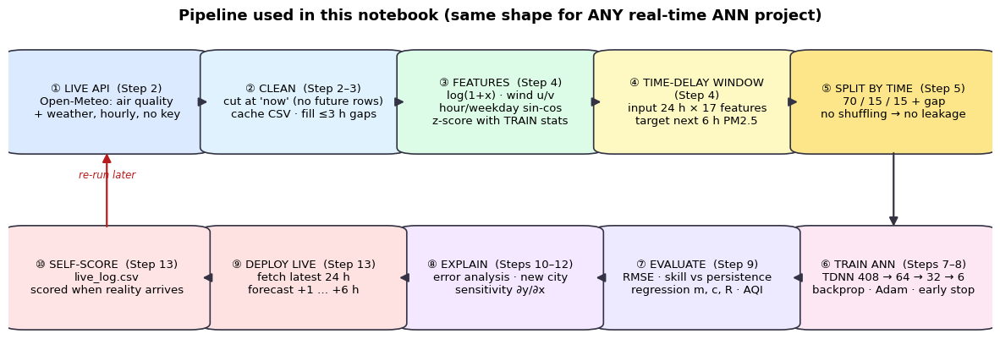

In [3]:
fig, ax = plt.subplots(figsize=(15, 5)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
top = [("① LIVE API  (Step 2)\nOpen-Meteo: air quality\n+ weather, hourly, no key", "#dbeafe"),
       ("② CLEAN  (Step 2–3)\ncut at 'now' (no future rows)\ncache CSV · fill ≤3 h gaps", "#e0f2fe"),
       ("③ FEATURES  (Step 4)\nlog(1+x) · wind u/v\nhour/weekday sin-cos\nz-score with TRAIN stats", "#dcfce7"),
       ("④ TIME-DELAY WINDOW\n(Step 4)\ninput 24 h × 17 features\ntarget next 6 h PM2.5", "#fef9c3"),
       ("⑤ SPLIT BY TIME  (Step 5)\n70 / 15 / 15 + gap\nno shuffling → no leakage", "#fde68a")]
bot = [("⑥ TRAIN ANN  (Steps 7–8)\nTDNN 408 → 64 → 32 → 6\nbackprop · Adam · early stop", "#fce7f3"),
       ("⑦ EVALUATE  (Step 9)\nRMSE · skill vs persistence\nregression m, c, R · AQI", "#ede9fe"),
       ("⑧ EXPLAIN  (Steps 10–12)\nerror analysis · new city\nsensitivity ∂y/∂x", "#f3e8ff"),
       ("⑨ DEPLOY LIVE  (Step 13)\nfetch latest 24 h\nforecast +1 … +6 h", "#fee2e2"),
       ("⑩ SELF-SCORE  (Step 13)\nlive_log.csv\nscored when reality arrives", "#ffe4e6")]
xs, w, h = [0.005, 0.205, 0.405, 0.605, 0.805], 0.19, 0.3
for x, (t, c) in zip(xs, top): box(ax, x, 0.62, w, h, t, c)
for x, (t, c) in zip(xs[::-1], bot): box(ax, x, 0.08, w, h, t, c)
for a, b in zip(xs[:-1], xs[1:]): arrow(ax, (a + w, 0.77), (b, 0.77)); arrow(ax, (b, 0.23), (a + w, 0.23))
arrow(ax, (xs[-1] + w / 2, 0.62), (xs[-1] + w / 2, 0.38))
arrow(ax, (xs[0] + w / 2, 0.38), (xs[0] + w / 2, 0.62), "re-run later", c="#b91c1c")
ax.set_title("Pipeline used in this notebook (same shape for ANY real-time ANN project)", fontsize=13, fontweight="bold")
plt.show()

### Recipe: adapting this to *your* real-time dataset
| Decide | This sample | Your project (examples) |
|---|---|---|
| Live source + "now" | Open-Meteo API, current hour | OpenAQ, USGS quakes, `yfinance`, ThingSpeak IoT, traffic or energy APIs |
| What to predict | PM2.5 for the next 6 h | Price tomorrow, load next hour, quake magnitude class, sensor fault yes/no |
| Problem type | Prediction (regression) | Fitting → linear + MSE; classes → softmax + cross-entropy |
| Input window | 24 h × 17 features | Last *N* readings of the useful variables |
| Simple baseline | Persistence | Persistence, moving average, majority class, linear regression |
| Split | By time, with a gap | By time (and by device, person or place, if your data has them) |
| Live proof | Forecast now, score later | The same: log the predictions and score them when the truth arrives |

## Step 1 — Frame the problem (fill this in *before* coding)
🔁 **CHANGE FOR YOUR THEME** — this is your plan card.

| Question | Sample answer |
|---|---|
| Input | The last 24 hours × 17 features: 6 pollutants, 7 weather variables, 4 clock features (hour and weekday as sin/cos) |
| Output | PM2.5 (µg/m³) for each hour from +1 h to +6 h (6 numbers) |
| Problem type | **Prediction / fitting** (regression) → linear output, MSE loss, time-delay input |
| Main metric | RMSE at +6 h, reported as **skill = 1 − RMSE_model / RMSE_persistence** |
| Operating condition that makes it hard | Forecast horizon (+1 h is easy, +6 h is hard), rain, morning and evening rush hours, smog episodes |
| Foundation | Skill ≥ 10% at +6 h on the held-out last 15% of the year |
| Advanced | Error vs horizon and vs hour of day; AQI category accuracy; explain where the model fails |
| Hard path | Train on Bengaluru only, then forecast **Delhi** (values 5–10× higher) and still beat persistence |

Problem type → network choice (Unit 5): **fitting** → linear output + MSE · **pattern recognition** → softmax + cross-entropy · **clustering** → SOFM / competitive · **prediction** → time-delay input (TDNN / NARX). This sample is a prediction problem, so the input is a window of past values (a *tapped delay line*).

## Step 2 — Load the data (live from an API)
🔁 **CHANGE FOR YOUR THEME** — replace the URL and variable names with your data source.

We call two free Open-Meteo endpoints for the same coordinates and join them on time:

* **Air quality** — PM2.5, PM10, CO, NO₂, SO₂, O₃ (hourly)
* **Weather** — temperature, humidity, wind speed and direction, rain, pressure, boundary-layer height (the height of the mixing layer; a low layer traps pollution)

Two rules for live data:
1. **Cut at "now".** The APIs also return *future* (forecast) hours. If you train on those, you leak information, so we keep only rows with time ≤ the current hour.
2. **Cache what you downloaded.** Each download is saved to `data_cache/`. If the internet or API fails during judging, the notebook loads the last cache, so *Run all* still works.

Other real-time sources for other themes: **OpenAQ** (real ground stations, free API key), **data.gov.in / CPCB** (Indian stations), **USGS earthquake feed**, **NSE/Yahoo** prices (`yfinance`), **ThingSpeak** IoT channels.

In [4]:
AQ_URL      = "https://air-quality-api.open-meteo.com/v1/air-quality"
WX_HIST_URL = "https://historical-forecast-api.open-meteo.com/v1/forecast"   # past weather, long range
WX_LIVE_URL = "https://api.open-meteo.com/v1/forecast"                       # last days + forecast
AQ_VARS = ["pm2_5", "pm10", "carbon_monoxide", "nitrogen_dioxide", "sulphur_dioxide", "ozone"]
WX_VARS = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "wind_direction_10m",
           "precipitation", "surface_pressure", "boundary_layer_height"]
CACHE = "data_cache"; os.makedirs(CACHE, exist_ok=True)

def now_local():
    return pd.Timestamp.now(tz=CONFIG["timezone"]).floor("h").tz_localize(None)

def get_hourly(url, params, tries=3):
    for k in range(tries):
        try:
            r = requests.get(url, params=params, timeout=60); r.raise_for_status()
            d = pd.DataFrame(r.json()["hourly"]); d["time"] = pd.to_datetime(d["time"])
            return d.set_index("time")
        except Exception as e:
            print(f"  attempt {k+1} failed: {e}"); time.sleep(3)
    raise ConnectionError(url)

def fetch_city(city, days=CONFIG["history_days"]):
    # Download `days` of hourly air quality + weather up to now. Falls back to the newest cache file.
    end = now_local(); start = end - pd.Timedelta(days=days)
    p = dict(latitude=city["lat"], longitude=city["lon"], timezone=CONFIG["timezone"],
             start_date=str(start.date()), end_date=str(end.date()))
    try:
        aq = get_hourly(AQ_URL, {**p, "hourly": ",".join(AQ_VARS)})
        wx = get_hourly(WX_HIST_URL, {**p, "hourly": ",".join(WX_VARS)})
        df = aq.join(wx, how="inner")
        df = df[df.index <= end]                         # rule 1: no future rows
        path = f"{CACHE}/{city['name']}_{end:%Y%m%d_%H}.csv"; df.to_csv(path)
        print(f"{city['name']}: LIVE download, {len(df)} hours up to {df.index[-1]}  -> cached {path}")
    except Exception as e:                               # rule 2: offline fallback
        files = sorted(glob.glob(f"{CACHE}/{city['name']}_*.csv"))
        if not files: raise RuntimeError("No internet and no cache. Run once while online.") from e
        df = pd.read_csv(files[-1], index_col=0, parse_dates=True)
        print(f"{city['name']}: API unavailable, using CACHE {files[-1]} (up to {df.index[-1]})")
    return df

raw = fetch_city(CONFIG["city"])
raw.tail(3)

Bengaluru: LIVE download, 8782 hours up to 2026-11-27 21:00:00  -> cached data_cache/Bengaluru_20261127_21.csv


,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_direction_10m,precipitation,surface_pressure,boundary_layer_height
time,,,,,,,,,,,,,
2026-11-27 19:00:00,17.1,17.2,657.0,42.7,10.4,26.0,23.0,79,11.3,80,0.0,916.9,415.0
2026-11-27 20:00:00,18.1,18.3,527.0,43.9,11.5,23.0,22.7,83,12.9,97,0.0,917.7,540.0
2026-11-27 21:00:00,16.2,16.4,450.0,38.9,11.3,27.0,21.5,89,12.1,100,0.0,917.9,435.0


## Step 3 — Explore the data
Look before you train. **How much data is missing? Is PM2.5 skewed? Is there a daily cycle?** The answers decide the preprocessing: skewed values → log transform, daily cycle → hour-of-day feature.

Hours: 8782 | missing values per column:
 {'pm2_5': 0, 'pm10': 0, 'carbon_monoxide': 0, 'nitrogen_dioxide': 0, 'sulphur_dioxide': 0, 'ozone': 0, 'temperature_2m': 0, 'relative_humidity_2m': 0, 'wind_speed_10m': 0, 'wind_direction_10m': 0, 'precipitation': 0, 'surface_pressure': 0, 'boundary_layer_height': 0}

PM2.5 µg/m³: min 1.3  median 20.0  max 95.2


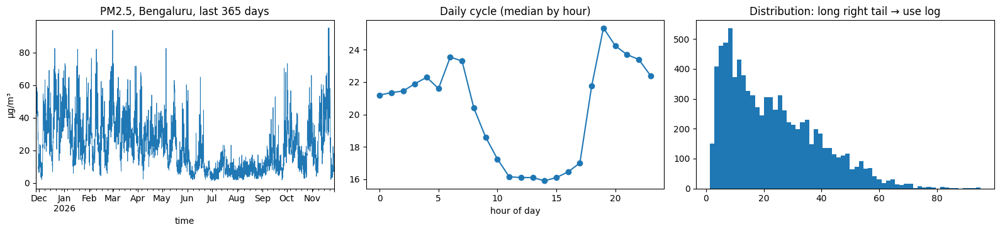

Correlation with PM2.5:
 {'wind_direction_10m': -0.46, 'wind_speed_10m': -0.4, 'temperature_2m': -0.19, 'boundary_layer_height': -0.18, 'relative_humidity_2m': -0.17, 'precipitation': -0.12, 'ozone': 0.27, 'surface_pressure': 0.29, 'nitrogen_dioxide': 0.45, 'carbon_monoxide': 0.5, 'sulphur_dioxide': 0.7, 'pm10': 0.96}


In [5]:
print("Hours:", len(raw), "| missing values per column:\n", raw.isna().sum().to_dict())
print("\nPM2.5 µg/m³: min %.1f  median %.1f  max %.1f" % (raw.pm2_5.min(), raw.pm2_5.median(), raw.pm2_5.max()))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
raw.pm2_5.plot(ax=ax[0], lw=.6); ax[0].set_title(f"PM2.5, {CONFIG['city']['name']}, last {CONFIG['history_days']} days"); ax[0].set_ylabel("µg/m³")
raw.groupby(raw.index.hour).pm2_5.median().plot(ax=ax[1], marker="o")
ax[1].set_title("Daily cycle (median by hour)"); ax[1].set_xlabel("hour of day")
ax[2].hist(raw.pm2_5.dropna(), bins=60); ax[2].set_title("Distribution: long right tail → use log")
plt.tight_layout(); plt.show()
print("Correlation with PM2.5:\n", raw.corr()["pm2_5"].drop("pm2_5").round(2).sort_values().to_dict())

## Step 4 — Preprocess
Three Unit 5 ideas:

* **Log transform**: pollutant values have a long tail, so we use log(1 + x). A rise from 20 to 40 then counts the same as a rise from 100 to 200.
* **Normalization**: pⁿ = (p − mean) / std, using **training-period statistics only**. Using the full-year mean would leak future information into training.
* **Time-delay windows (TDNN)**: each input is a 24-hour × 17-feature block, and each target is the next 6 hours of PM2.5.

Wind direction is an angle (359° is next to 1°), so we convert it to u/v wind components. Hour and weekday become sin/cos pairs so that 23:00 sits next to 00:00.

🔁 **CHANGE FOR YOUR THEME**: images → divide by 255; tabular → standardize each column with training statistics only.

In [6]:
LOG_COLS = AQ_VARS + ["precipitation", "boundary_layer_height"]

def make_features(df):
    d = df.copy().asfreq("h").interpolate(limit=3)           # fill short gaps only (≤ 3 h)
    for c in LOG_COLS: d[c] = np.log1p(d[c].clip(lower=0))
    rad = np.deg2rad(d.pop("wind_direction_10m"))
    d["wind_u"] = d["wind_speed_10m"] * np.sin(rad); d["wind_v"] = d["wind_speed_10m"] * np.cos(rad)
    d = d.drop(columns="wind_speed_10m")
    h, w = d.index.hour, d.index.dayofweek
    d["hour_sin"], d["hour_cos"] = np.sin(2*np.pi*h/24), np.cos(2*np.pi*h/24)
    d["dow_sin"],  d["dow_cos"]  = np.sin(2*np.pi*w/7),  np.cos(2*np.pi*w/7)
    return d

feat = make_features(raw)
FEATURES = list(feat.columns); PM = FEATURES.index("pm2_5")
W, H = CONFIG["window"], CONFIG["horizon"]

def make_windows(F):
    # F: (T, n_features) scaled array -> X (N, W, n), Y (N, H) future scaled log-PM2.5, end index of each window
    from numpy.lib.stride_tricks import sliding_window_view
    X = sliding_window_view(F[:-H], (W, F.shape[1]))[:, 0]
    Y = sliding_window_view(F[W:, PM], H)
    ends = np.arange(W - 1, len(F) - H)
    ok = ~(np.isnan(X).any((1, 2)) | np.isnan(Y).any(1))
    return X[ok].astype("float32"), Y[ok].astype("float32"), ends[ok]

print(f"{len(FEATURES)} features:", FEATURES)

17 features: ['pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'surface_pressure', 'boundary_layer_height', 'wind_u', 'wind_v', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']


#### 🎬 Animation: how one year of hourly data becomes thousands of training pairs
The **blue** box is the time-delay window, the 24 hours the network sees as input **p**. The **orange** box holds the 6 hours it must predict, the target **t**. Sliding the window by one hour gives a new training pair, so one year of data gives about 8,700 pairs. The heat-map at the bottom shows the actual input matrix the network receives at each position.

In [7]:
seg = feat.iloc[-24 * 10:]; pm_seg = raw.pm2_5.reindex(seg.index).to_numpy()
Z = ((seg - seg.mean()) / seg.std().replace(0, 1)).to_numpy().T
fig = plt.figure(figsize=(13, 6.4), dpi=72)
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25], width_ratios=[3.2, 1])
a0, a1, a2 = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
a0.plot(pm_seg, "k", lw=1); a0.set_ylabel("PM2.5 µg/m³")
days = np.arange(0, len(seg), 24); a0.set_xticks(days); a0.set_xticklabels([f"{t:%d %b}" for t in seg.index[days]])
rin = Rectangle((0, 0), W, 1, transform=a0.get_xaxis_transform(), color="tab:blue", alpha=.25)
rout = Rectangle((W, 0), H, 1, transform=a0.get_xaxis_transform(), color="tab:orange", alpha=.5)
a0.add_patch(rin); a0.add_patch(rout)
im = a1.imshow(Z[:, :W], aspect="auto", cmap="coolwarm", vmin=-2.5, vmax=2.5)
a1.set_yticks(range(len(FEATURES))); a1.set_yticklabels(FEATURES, fontsize=7)
a1.set_xlabel("hour inside the window (0 = oldest, 23 = now)")
a1.set_title(f"INPUT p: {W} × {len(FEATURES)} matrix → flattened to {W*len(FEATURES)} numbers", fontsize=10)
bars = a2.bar([f"+{h+1}h" for h in range(H)], pm_seg[W:W + H], color="tab:orange")
a2.set_ylim(0, np.nanmax(pm_seg) * 1.1); a2.set_title("TARGET t: next 6 h", fontsize=10)

def upd(s):
    rin.set_x(s); rout.set_x(s + W); im.set_data(Z[:, s:s + W])
    for b, v in zip(bars, pm_seg[s + W:s + W + H]): b.set_height(v)
    a0.set_title(f"Sliding the time-delay window · forecast issued {seg.index[s + W - 1]:%d %b %H:00}"
                 "   (blue = what the ANN sees, orange = what it must predict)", fontsize=10)
    return [rin, rout, im, *bars]

upd(0); plt.tight_layout()
show_anim(fig, animation.FuncAnimation(fig, upd, frames=range(0, len(seg) - W - H, 6)))

## Step 5 — Split into training / validation / test **by time** (70 / 15 / 15)
* **Never shuffle a time series before splitting.** Neighbouring windows share 23 of their 24 hours. With a random split, the test set would be almost a copy of the training set, and the score would look much better than it really is.
* So we train on the **oldest 70%**, validate on the next 15%, and test on the **most recent 15%**. That matches real use: you learn from the past and forecast the future.
* We leave a **gap of W + H hours** between the sets so that no hour appears in two of them.
* The scaler (mean and std) is fitted on the training period only, then applied to everything.

train 6118 | val 1258 | test 1259   (window 24 h × 17 features)
train : 2025-11-27 23:00:00 → 2026-08-09 20:00:00
test  : 2026-10-06 05:00:00 → 2026-11-27 15:00:00


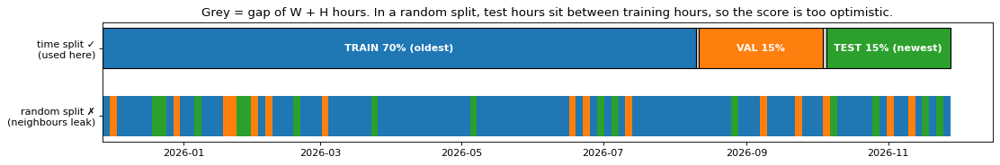

In [8]:
T = len(feat); gap = W + H
t_tr, t_va = int(T * 0.70), int(T * 0.85)
mu = feat.iloc[:t_tr].mean(); sd = feat.iloc[:t_tr].std().replace(0, 1)
scale = lambda d: ((d[FEATURES] - mu[FEATURES]) / sd[FEATURES]).to_numpy("float32")
to_ugm3 = lambda z: np.expm1(z * sd["pm2_5"] + mu["pm2_5"])          # scaled log-PM -> µg/m³

Xall, Yall, ends = make_windows(scale(feat))
tr = ends + H < t_tr                                   # target hours inside the training period
va = (ends - W + 1 >= t_tr + gap) & (ends + H < t_va)
te = ends - W + 1 >= t_va + gap
Xtr, Ytr, Xva, Yva, Xte, Yte = Xall[tr], Yall[tr], Xall[va], Yall[va], Xall[te], Yall[te]
time_te = feat.index[ends[te]]                         # "issue time" of each test forecast
time_va = feat.index[ends[va]]
print(f"train {len(Xtr)} | val {len(Xva)} | test {len(Xte)}   (window {W} h × {len(FEATURES)} features)")
print("train :", feat.index[ends[tr][0]], "→", feat.index[ends[tr][-1]])
print("test  :", time_te[0], "→", time_te[-1])
assert ends[tr].max() + H < ends[te].min() - W + 1, "LEAK: train and test share hours!"

fig, ax = plt.subplots(figsize=(14, 2.4), dpi=80); ti = feat.index; d = mdates.date2num
for a, b, c, lab in [(0, t_tr, "tab:blue", "TRAIN 70% (oldest)"), (t_tr, t_tr + gap, "lightgray", ""),
                     (t_tr + gap, t_va, "tab:orange", "VAL 15%"), (t_va, t_va + gap, "lightgray", ""),
                     (t_va + gap, T - 1, "tab:green", "TEST 15% (newest)")]:
    ax.barh(1, d(ti[b]) - d(ti[a]), left=d(ti[a]), color=c, edgecolor="k", height=.6)
    if lab: ax.text(d(ti[a]) + (d(ti[b]) - d(ti[a])) / 2, 1, lab, ha="center", va="center", color="w", fontweight="bold")
edges = pd.date_range(ti[0], ti[-1], periods=121); cols = np.random.RandomState(0).choice(["tab:blue", "tab:orange", "tab:green"], 120, p=[.7, .15, .15])
for k in range(120): ax.barh(0, d(edges[k + 1]) - d(edges[k]), left=d(edges[k]), color=cols[k], height=.6)
ax.set_yticks([0, 1]); ax.set_yticklabels(["random split ✗\n(neighbours leak)", "time split ✓\n(used here)"])
ax.xaxis_date(); ax.set_title("Grey = gap of W + H hours. In a random split, test hours sit between training hours, so the score is too optimistic.")
plt.tight_layout(); plt.show()

## Step 6 — Baselines first
A forecast is only useful if it beats something simple:

* **Persistence**: PM2.5 in *h* hours = PM2.5 now. This is very hard to beat at +1 h.
* **Linear regression (ridge)** on the same 24-hour window: a linear TDNN with no hidden layer.

**Skill** = 1 − RMSE_model / RMSE_persistence. 0 means no better than persistence, and 0.2 means 20% lower error.

In [9]:
def rmse_by_h(Ytrue_s, Ypred_s):
    yt, yp = to_ugm3(Ytrue_s), to_ugm3(Ypred_s)
    return np.sqrt(((yt - yp) ** 2).mean(0))

persist = lambda X: np.repeat(X[:, -1, PM][:, None], H, 1)
r_persist = rmse_by_h(Yte, persist(Xte))
ridge = Ridge(alpha=10).fit(Xtr.reshape(len(Xtr), -1), Ytr)
r_ridge = rmse_by_h(Yte, ridge.predict(Xte.reshape(len(Xte), -1)))
print("RMSE µg/m³ by horizon (+1 … +6 h)")
print("  persistence:", r_persist.round(2))
print("  ridge      :", r_ridge.round(2), f"  skill@+{H}h = {1 - r_ridge[-1]/r_persist[-1]:.3f}")

RMSE µg/m³ by horizon (+1 … +6 h)
  persistence: [ 3.91  6.58  8.65 10.23 11.38 12.16]
  ridge      : [3.41 5.35 6.77 7.86 8.61 9.08]   skill@+6h = 0.254


## Step 7 — Build the network
🔁 **CHANGE FOR YOUR THEME**: choose by input type:

| Input | Good first network |
|---|---|
| Window of a time series (this sample) | **TDNN / MLP** on the flattened window, or a small LSTM |
| 1-D signal (ECG, I/Q, vibration, audio) | 1-D CNN |
| Image (leaves, roads) | Pretrained CNN (MobileNetV2) + new head |
| Table of numbers | MLP: Dense(64, relu) → Dense(32, relu) → output |

Design notes: **ReLU** hidden layers, a **linear output** layer (this is regression, so no softmax), and **one output neuron per forecast hour**, so a single network predicts all 6 hours. **Dropout** and a small **L2 weight decay** fight overfitting. Weights start with **Glorot uniform** initialization.

In [10]:
def build_model(kind=CONFIG["model"], n_feat=len(FEATURES)):
    inp = keras.Input((W, n_feat))
    if kind == "lstm":
        x = layers.LSTM(32)(inp)
    else:                                                     # TDNN: tapped delay line -> MLP
        x = layers.Flatten()(inp)
        x = layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4))(x)
        x = layers.Dropout(0.2)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(H, activation="linear")(x)            # 6 outputs: +1 h … +6 h
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(CONFIG["learning_rate"]), loss="mse", metrics=["mae"])
    return m

model = build_model()
model.summary()
print("Parameters:", model.count_params())

Model: "model"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 input_1 (InputLayer)        [(None, 24, 17)]          0         


 flatten (Flatten)           (None, 408)               0         


 dense (Dense)               (None, 64)                26176     


... (4 outputs left out)

Trainable params: 28454 (111.15 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


Parameters: 28454


#### 🏗️ Architecture of the network we just built
The diagram is drawn from the real model, so the layer sizes and weight counts update automatically if you change `build_model`. Only a few neurons per layer are drawn; the label says how many there really are.

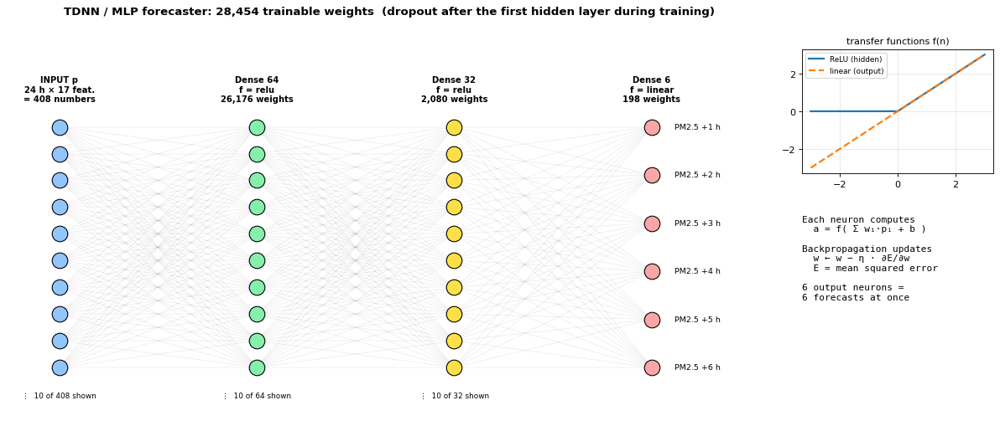

In [11]:
def net_spec(m):
    spec = [(f"INPUT p\n{W} h × {len(FEATURES)} feat.\n= {W*len(FEATURES)} numbers", W * len(FEATURES), None)]
    for l in m.layers:
        if isinstance(l, (layers.Dense, layers.LSTM)):
            act = "LSTM cell" if isinstance(l, layers.LSTM) else l.activation.__name__
            spec.append((f"{type(l).__name__} {l.units}\nf = {act}\n{l.count_params():,} weights", l.units, l))
    return spec

def draw_net(ax, spec, max_show=10):
    ax.axis("off"); xs = np.linspace(0.07, 0.86, len(spec)); pos, idxs, scat = [], [], []
    for x, (_, n, _) in zip(xs, spec):
        k = min(n, max_show); pos.append((x, np.linspace(0.86, 0.14, k) if k > 1 else np.array([.5])))
        idxs.append(np.linspace(0, n - 1, k).astype(int))
    for (x0, y0), (x1, y1) in zip(pos[:-1], pos[1:]):
        for a in y0:
            for b in y1: ax.plot([x0, x1], [a, b], c="gray", lw=.4, alpha=.25, zorder=1)
    pal = ["#93c5fd", "#86efac", "#fde047", "#fdba74", "#c4b5fd"]
    for li, ((x, ys), (label, n, _)) in enumerate(zip(pos, spec)):
        col = "#fca5a5" if li == len(spec) - 1 else pal[li % len(pal)]
        scat.append(ax.scatter([x] * len(ys), ys, s=280, c=col, edgecolors="k", zorder=3))
        if n > max_show: ax.text(x, 0.05, f"⋮  {len(ys)} of {n} shown", ha="center", fontsize=8)
        ax.text(x, 0.93, label, ha="center", va="bottom", fontsize=9, fontweight="bold")
    for h, y in enumerate(pos[-1][1]): ax.text(pos[-1][0] + 0.03, y, f"PM2.5 +{h+1} h", va="center", fontsize=8.5)
    ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.18)
    return scat, idxs

spec = net_spec(model)
fig = plt.figure(figsize=(15, 6.2), dpi=80); axN = fig.add_axes([0, 0, .76, .95])
draw_net(axN, spec)
axN.set_title(f"{'TDNN / MLP' if CONFIG['model']=='mlp' else 'LSTM'} forecaster: {model.count_params():,} trainable weights"
              "  (dropout after the first hidden layer during training)", fontsize=12, fontweight="bold")
axf = fig.add_axes([.79, .58, .19, .3]); n_ = np.linspace(-3, 3, 100)
axf.plot(n_, np.maximum(0, n_), lw=2, label="ReLU (hidden)"); axf.plot(n_, n_, "--", lw=2, label="linear (output)")
axf.legend(fontsize=8); axf.grid(alpha=.3); axf.set_title("transfer functions f(n)", fontsize=10)
fig.text(.79, .48, "Each neuron computes\n  a = f( Σ wᵢ·pᵢ + b )\n\nBackpropagation updates\n  w ← w − η · ∂E/∂w\n  E = mean squared error\n\n6 output neurons =\n6 forecasts at once",
         fontsize=10, va="top", family="monospace")
plt.show()

## Step 8 — Train with early stopping
Backpropagation with the Adam optimizer. **Early stopping** watches the validation loss and keeps the weights from the best epoch (Unit 5, stopping criteria).

trained 22 epochs in 9s


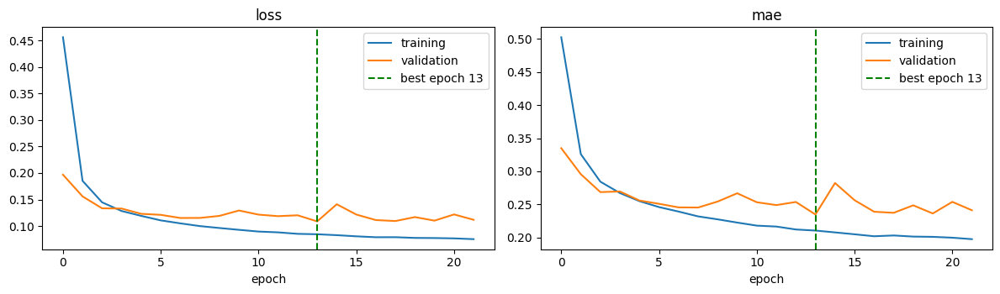

If validation loss rises while training loss keeps falling → overfitting.


In [12]:
def train(m, Xa, ya, Xv, yv, verbose=0, extra_callbacks=()):
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["patience"], restore_best_weights=True)
    t0 = time.time()
    h = m.fit(Xa, ya, validation_data=(Xv, yv), epochs=CONFIG["epochs"], batch_size=CONFIG["batch_size"],
              callbacks=[es, *extra_callbacks], verbose=verbose, shuffle=True)       # shuffling *inside* the training set is fine
    print(f"trained {len(h.history['loss'])} epochs in {time.time()-t0:.0f}s")
    return h

class Snapshot(keras.callbacks.Callback):          # remember the +6 h forecast on one validation week after every epoch
    def __init__(self, X): super().__init__(); self.X, self.preds = X, []
    def on_epoch_end(self, epoch, logs=None): self.preds.append(self.model.predict(self.X, verbose=0)[:, -1])

snap = Snapshot(Xva[:24 * 7])
hist = train(model, Xtr, Ytr, Xva, Yva, extra_callbacks=[snap])
best = int(np.argmin(hist.history["val_loss"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k, a in zip(["loss", "mae"], ax):
    a.plot(hist.history[k], label="training"); a.plot(hist.history["val_" + k], label="validation")
    a.axvline(best, ls="--", c="g", label=f"best epoch {best}"); a.set_title(k); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()
print("If validation loss rises while training loss keeps falling → overfitting.")

#### 🎬 Animation: watch the network learn
Each frame is one **epoch** (one pass of backpropagation over all training pairs). Left: the +6 h forecast for one validation week, starting from random weights. Right: the error curves. The forecast first learns the average level, then the daily cycle, then the peaks.

In [13]:
wk_true = to_ugm3(Yva[:24 * 7, -1]); wk_t = time_va[:24 * 7] + pd.Timedelta(hours=H)
ep = np.unique(np.linspace(0, len(snap.preds) - 1, min(40, len(snap.preds))).astype(int))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), dpi=72, gridspec_kw=dict(width_ratios=[2, 1]))
ax[0].plot(wk_t, wk_true, "k", lw=1.5, label="actual")
ln, = ax[0].plot(wk_t, to_ugm3(snap.preds[0]), "r", lw=1.5, label="ANN forecast +6 h")
ax[0].set_ylim(0, wk_true.max() * 1.5); ax[0].legend(loc="upper left"); ax[0].set_ylabel("PM2.5 µg/m³"); ax[0].tick_params(axis="x", rotation=20)
L, VL = hist.history["loss"], hist.history["val_loss"]
ax[1].plot(L, c="tab:blue", alpha=.2); ax[1].plot(VL, c="tab:orange", alpha=.2)
lt, = ax[1].plot([], [], c="tab:blue", label="training loss"); lv, = ax[1].plot([], [], c="tab:orange", label="validation loss")
dot = ax[1].axvline(0, c="g", ls="--"); ax[1].set_xlabel("epoch"); ax[1].set_yscale("log"); ax[1].legend()
def upd(e):
    ln.set_ydata(to_ugm3(snap.preds[e])); lt.set_data(range(e + 1), L[:e + 1]); lv.set_data(range(e + 1), VL[:e + 1]); dot.set_xdata([e, e])
    ax[0].set_title(f"epoch {e + 1}/{len(L)} · validation MAE {np.abs(to_ugm3(snap.preds[e]) - wk_true).mean():.1f} µg/m³")
    return ln, lt, lv, dot
upd(ep[0]); plt.tight_layout(); show_anim(fig, animation.FuncAnimation(fig, upd, frames=ep), fps=5)

#### 🎬 Animation: one forecast flowing through the network (forward pass)
For a few real validation windows, the frames light up the layers one at a time. Node colour shows how active each neuron is, computed as a = f(Wp + b). ReLU neurons with a = 0 are "off" (dark). In the last frame, the 6 output neurons turn into the forecast on the right.

In [14]:
lay = [s[2] for s in spec[1:]]
probe = keras.Model(model.inputs, [l.output for l in lay])
pick = np.linspace(0, len(Xva) - 1, 5).astype(int)
acts = probe.predict(Xva[pick], verbose=0); acts = acts if isinstance(acts, list) else [acts]
vals = [Xva[pick].reshape(len(pick), -1)] + [np.asarray(a) for a in acts]
fig = plt.figure(figsize=(15, 5.6), dpi=72)
axN = fig.add_axes([0, 0, .64, .9]); axS = fig.add_axes([.69, .14, .29, .66])
scat, idxs = draw_net(axN, spec); cm = plt.cm.viridis; cd = plt.cm.coolwarm
frames = [(s, st) for s in range(len(pick)) for st in range(len(spec) + 1)]
def upd(fr):
    s, st = fr
    for li, sc in enumerate(scat):
        if li <= st:
            v = vals[li][s, idxs[li]]; vmax = np.abs(vals[li]).max() + 1e-9
            sc.set_facecolor(cd(0.5 + 0.5 * v / vmax) if li in (0, len(spec) - 1) else cm(v / vmax))
        else: sc.set_facecolor("#e5e7eb")
    stage = "input window" if st == 0 else ("forecast ready" if st >= len(spec) else f"layer {st}: a = f(W·p + b)")
    axN.set_title(f"Forward pass · sample {s + 1}/{len(pick)} · {stage}", fontsize=12, fontweight="bold")
    k = pick[s]; t0 = time_va[k]; axS.cla()
    axS.plot(range(-W + 1, 1), to_ugm3(Xva[k, :, PM]), "k", label="input: past 24 h")
    if st >= len(spec) - 1:
        axS.plot(range(1, H + 1), to_ugm3(Yva[k]), "g.-", label="actual")
        axS.plot(range(1, H + 1), to_ugm3(model.predict(Xva[k:k + 1], verbose=0)[0]), "ro-", label="forecast")
    axS.axvline(0, c="gray", ls=":"); axS.set_xlim(-W, H + 1); axS.set_xlabel("hours from now"); axS.set_ylabel("PM2.5 µg/m³")
    axS.set_title(f"issued {t0:%d %b %H:00}", fontsize=10); axS.legend(fontsize=8, loc="upper left")
show_anim(fig, animation.FuncAnimation(fig, upd, frames=frames), fps=2)

## Step 9 — Evaluate on the test set (once!)
Unit 5 post-training analysis for **fitting / prediction**:
* RMSE and MAE per horizon, in real units (µg/m³), and skill compared with persistence
* **Regression of output vs target**: slope *m*, offset *c* and correlation *R*. A perfect model has m = 1, c = 0, R = 1.
* **Indian AQI category** (CPCB PM2.5 breakpoints): does the forecast put the hour in the right category? The confusion matrix shows this.

Look at the skill row carefully. The plain network can **lose to persistence at +1 h**, because it has to rebuild "the next hour ≈ now" from scratch. That is a finding to explain, not to hide. Step 11 shows a design that fixes it.

horizon        : ['+1h', '+2h', '+3h', '+4h', '+5h', '+6h']
RMSE NN        : [5.13 6.03 7.03 7.96 8.51 8.84]
RMSE persist   : [ 3.91  6.58  8.65 10.23 11.38 12.16]
MAE  NN        : [3.46 4.02 4.68 5.31 5.77 6.21]
skill vs pers. : [-0.311  0.084  0.187  0.222  0.252  0.273]

skill @+6h = 0.273  (Foundation target 0.1) -> PASS


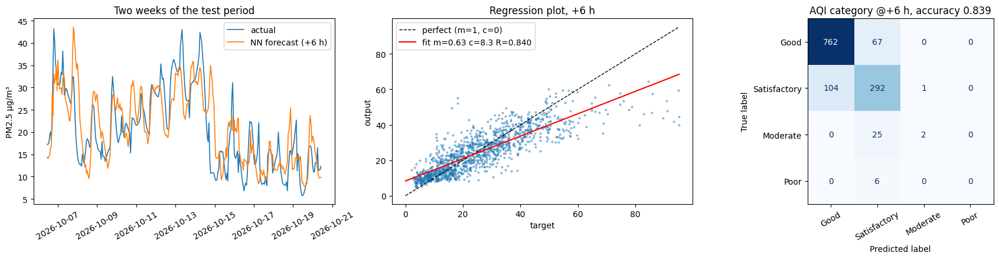

In [15]:
P_te = model.predict(Xte, verbose=0)
yt, yp = to_ugm3(Yte), to_ugm3(P_te)
r_nn = rmse_by_h(Yte, P_te); mae_nn = np.abs(yt - yp).mean(0)
skill = 1 - r_nn / r_persist
print("horizon        :", [f"+{h+1}h" for h in range(H)])
print("RMSE NN        :", r_nn.round(2)); print("RMSE persist   :", r_persist.round(2))
print("MAE  NN        :", mae_nn.round(2)); print("skill vs pers. :", skill.round(3))
print(f"\nskill @+{H}h = {skill[-1]:.3f}  (Foundation target {CONFIG['target_value']}) -> "
      f"{'PASS' if skill[-1] >= CONFIG['target_value'] else 'BELOW TARGET'}")

AQI_BINS = [0, 30, 60, 90, 120, 250, np.inf]
AQI_NAMES = ["Good", "Satisfactory", "Moderate", "Poor", "Very poor", "Severe"]
aqi_cat = lambda v: np.digitize(v, AQI_BINS[1:-1], right=True)
c_true, c_pred = aqi_cat(yt[:, -1]), aqi_cat(yp[:, -1])
cat_acc = (c_true == c_pred).mean()

m_, c_ = np.polyfit(yt[:, -1], yp[:, -1], 1); R = np.corrcoef(yt[:, -1], yp[:, -1])[0, 1]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
n = min(24 * 14, len(time_te))
ax[0].plot(time_te[:n] + pd.Timedelta(hours=H), yt[:n, -1], label="actual", lw=1.2)
ax[0].plot(time_te[:n] + pd.Timedelta(hours=H), yp[:n, -1], label=f"NN forecast (+{H} h)", lw=1.2)
ax[0].set_title("Two weeks of the test period"); ax[0].set_ylabel("PM2.5 µg/m³"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)
ax[1].scatter(yt[:, -1], yp[:, -1], s=4, alpha=.4); lim = [0, max(yt.max(), yp.max())]
ax[1].plot(lim, lim, "k--", lw=1, label="perfect (m=1, c=0)")
ax[1].plot(lim, np.polyval([m_, c_], lim), "r", label=f"fit m={m_:.2f} c={c_:.1f} R={R:.3f}")
ax[1].set_xlabel("target"); ax[1].set_ylabel("output"); ax[1].set_title(f"Regression plot, +{H} h"); ax[1].legend()
present = sorted(set(c_true) | set(c_pred))
ConfusionMatrixDisplay(confusion_matrix(c_true, c_pred, labels=present),
                       display_labels=[AQI_NAMES[i] for i in present]).plot(ax=ax[2], cmap="Blues", colorbar=False)
ax[2].set_title(f"AQI category @+{H} h, accuracy {cat_acc:.3f}"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

#### 🎬 Animation: replaying the test week as if it were live
This is what the forecaster would have shown, hour by hour, during the newest week of data, which it has never seen. **Black**: the 24 hours it sees. **Red**: its forecast. **Green**: what really happened. **Blue dashed**: persistence. Watch where red beats blue (smooth rises and falls) and where both fail (sudden jumps).

In [16]:
kf = np.arange(0, min(len(time_te), 24 * 7), 3)
t_all = pd.date_range(time_te[0] - pd.Timedelta(hours=W), time_te[kf[-1]] + pd.Timedelta(hours=H), freq="h")
fig, ax = plt.subplots(figsize=(14, 4.3), dpi=72)
ax.plot(t_all, raw.pm2_5.reindex(t_all), c="lightgray", lw=1, label="actual (whole week)")
past_l, = ax.plot([], [], "k", lw=2.2, label="input: last 24 h")
fut_l, = ax.plot([], [], "g.-", lw=2, label="what really happened")
pred_l, = ax.plot([], [], "ro-", lw=2, label="ANN forecast +1…+6 h")
per_l, = ax.plot([], [], "b--", lw=1.3, label="persistence")
now_l = ax.axvline(time_te[0], c="g", ls=":"); ax.legend(loc="upper left", fontsize=8, ncol=5); ax.set_ylabel("PM2.5 µg/m³")
def upd(k):
    t0 = time_te[k]; tp = pd.date_range(t0 - pd.Timedelta(hours=W - 1), t0, freq="h"); tf_ = tp[-1] + pd.to_timedelta(np.arange(1, H + 1), "h")
    past_l.set_data(tp, to_ugm3(Xte[k, :, PM])); fut_l.set_data(tf_, yt[k]); pred_l.set_data(tf_, yp[k])
    per_l.set_data(tf_, np.repeat(to_ugm3(Xte[k, -1, PM]), H)); now_l.set_xdata([t0, t0])
    ax.set_title(f"replay · now = {t0:%a %d %b %H:00} · MAE this forecast: ANN {np.abs(yp[k]-yt[k]).mean():.1f}"
                 f"  vs persistence {np.abs(to_ugm3(Xte[k, -1, PM]) - yt[k]).mean():.1f} µg/m³")
    return past_l, fut_l, pred_l, per_l, now_l
upd(kf[0]); plt.tight_layout(); show_anim(fig, animation.FuncAnimation(fig, upd, frames=kf), fps=4)

## Step 10 — Error analysis: *where* and *why* does it fail?
Judges give 20 marks for insight. Plot the error against the operating conditions and look at the worst forecasts.

🔁 Your condition might be: patient, motor load, city, speaker, light level, image class.

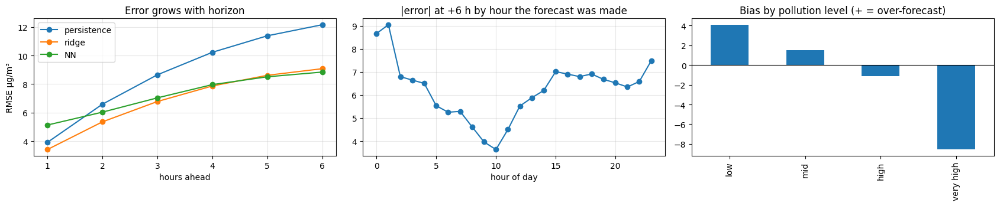

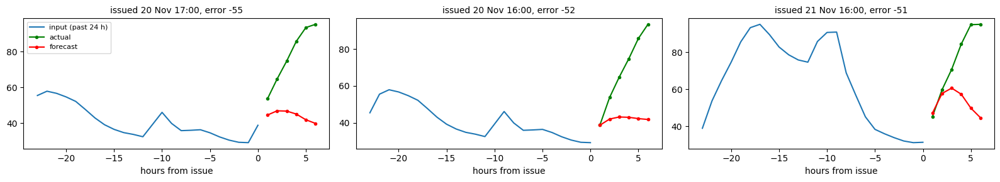

Typical story: sudden jumps (a change of wind or rain) can't be seen in the past 24 h. The weather forecast for the next hours would help (see 'ideas' at the end).


In [17]:
err = yp[:, -1] - yt[:, -1]
hour_issue = time_te.hour
level = pd.qcut(yt[:, -1], 4, labels=["low", "mid", "high", "very high"])
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
ax[0].plot(range(1, H+1), r_persist, "o-", label="persistence"); ax[0].plot(range(1, H+1), r_ridge, "o-", label="ridge")
ax[0].plot(range(1, H+1), r_nn, "o-", label="NN"); ax[0].set_xlabel("hours ahead"); ax[0].set_ylabel("RMSE µg/m³")
ax[0].set_title("Error grows with horizon"); ax[0].legend(); ax[0].grid(alpha=.3)
pd.Series(np.abs(err)).groupby(hour_issue).mean().plot(ax=ax[1], marker="o")
ax[1].set_title(f"|error| at +{H} h by hour the forecast was made"); ax[1].set_xlabel("hour of day"); ax[1].grid(alpha=.3)
pd.Series(err).groupby(level, observed=True).mean().plot.bar(ax=ax[2])
ax[2].axhline(0, c="k", lw=.8); ax[2].set_title("Bias by pollution level (+ = over-forecast)")
plt.tight_layout(); plt.show()

worst = np.argsort(-np.abs(err))[:3]
fig, ax = plt.subplots(1, 3, figsize=(16, 3))
for a, k in zip(ax, worst):
    past = to_ugm3(Xte[k, :, PM]); t0 = time_te[k]
    a.plot(range(-W + 1, 1), past, label="input (past 24 h)")
    a.plot(range(1, H + 1), yt[k], "g.-", label="actual"); a.plot(range(1, H + 1), yp[k], "r.-", label="forecast")
    a.set_title(f"issued {t0:%d %b %H:00}, error {err[k]:+.0f}", fontsize=10); a.set_xlabel("hours from issue")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print("Typical story: sudden jumps (a change of wind or rain) can't be seen in the past 24 h. The weather forecast for the next hours would help (see 'ideas' at the end).")

## Step 11 — Hard path: forecast a city the model has never seen
**The trap (Unit 5, extrapolation):** we train on Bengaluru and forecast **Delhi**. Delhi's PM2.5 is several times higher, but the biggest surprise is a feature nobody worries about: **surface pressure**. Bengaluru sits at 914 m altitude (about 910 hPa), and Delhi is near 215 m (about 990 hPa). After Bengaluru normalization, Delhi's pressure inputs are **dozens of standard deviations** outside anything seen in training, and a ReLU network extrapolates them linearly into nonsense. The diagnostic below finds this automatically. Always check input ranges before trusting a model somewhere new.

**The fix: make the problem scale-free and altitude-free.** This is the time-series version of the per-sample normalization in the waveform sample.
* Inputs: subtract the **current** value of every physical feature (pollutants *and* weather) from its 24-hour history. The network then sees *changes* ("pressure fell 2 hPa", "PM10 rose 30%"), and changes look alike in every city.
* Target: predict the **change** in log-PM2.5 from now to +h, then add the current value back. This also works as a skip connection, so the network no longer has to re-learn "the future ≈ now". That is why it also beats persistence at +1 h.

Delhi: LIVE download, 8782 hours up to 2026-11-27 21:00:00  -> cached data_cache/Delhi_20261127_21.csv
Delhi PM2.5 median 78 vs Bengaluru 20 µg/m³
Inputs outside the Bengaluru training range (std units beyond the edge):
 {'surface_pressure': 34.7, 'pm10': 4.2, 'sulphur_dioxide': 2.7, 'carbon_monoxide': 2.1, 'temperature_2m': 1.8, 'pm2_5': 1.7, 'ozone': 0.7, 'wind_v': 0.6}


trained 36 epochs in 10s



Delhi, never seen in training: RMSE @+6h (µg/m³) and skill vs persistence
  persistence            :   41.1
  absolute model (trap)  :   62.1   skill -0.509
  relative model (fix)   :   31.8   skill +0.227
  skill per horizon, fix: [0.065 0.098 0.131 0.165 0.199 0.227]
Home city (Bengaluru test) skill @+1h / @+6h: absolute -0.311 / +0.273 | relative +0.081 / +0.225


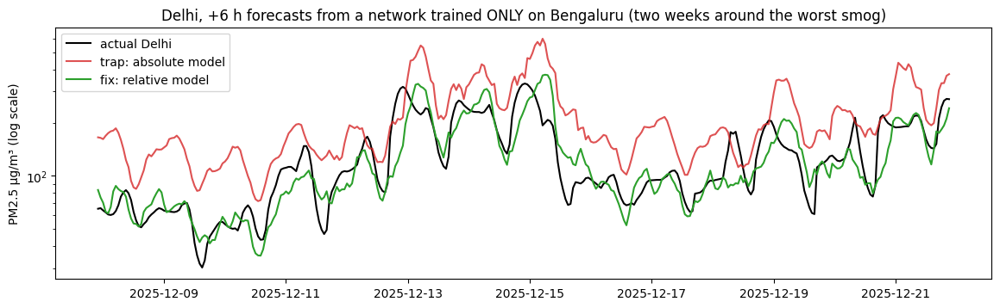

Model size: 28454 parameters


In [18]:
raw2 = fetch_city(CONFIG["new_city"])
X2, Y2, ends2 = make_windows(scale(make_features(raw2)))   # Delhi scaled with BENGALURU statistics
r2_persist = rmse_by_h(Y2, persist(X2))
print(f"Delhi PM2.5 median {raw2.pm2_5.median():.0f} vs Bengaluru {raw.pm2_5.median():.0f} µg/m³")

# Diagnostic: how far outside the training range is each input? (in training standard deviations)
over = pd.Series({f: max(X2[:, :, j].max() - Xtr[:, :, j].max(), Xtr[:, :, j].min() - X2[:, :, j].min(), 0)
                  for j, f in enumerate(FEATURES)}).sort_values(ascending=False)
print("Inputs outside the Bengaluru training range (std units beyond the edge):\n", over[over > 0.5].round(1).to_dict())

# (a) the trap: the absolute-level model from Step 8, unchanged
r2_trap = rmse_by_h(Y2, model.predict(X2, verbose=0))

# (b) the fix: every physical input relative to "now", target = change from now
PHYS = [j for j, f in enumerate(FEATURES) if not f.startswith(("hour_", "dow_"))]
def relative(X, Y=None):
    Xr = X.copy(); Xr[:, :, PHYS] -= X[:, -1:, PHYS]
    return (Xr, None) if Y is None else (Xr, Y - X[:, -1:, PM])
from_relative = lambda X, D: D + X[:, -1:, PM]

m_rel = build_model()
train(m_rel, *relative(Xtr, Ytr), *relative(Xva, Yva))
P2_fix = from_relative(X2, m_rel.predict(relative(X2)[0], verbose=0))
r2_fix = rmse_by_h(Y2, P2_fix)
r_rel_home = rmse_by_h(Yte, from_relative(Xte, m_rel.predict(relative(Xte)[0], verbose=0)))

sk = lambda r, rp: 1 - r[-1] / rp[-1]
print(f"\nDelhi, never seen in training: RMSE @+{H}h (µg/m³) and skill vs persistence")
print(f"  persistence            : {r2_persist[-1]:6.1f}")
print(f"  absolute model (trap)  : {r2_trap[-1]:6.1f}   skill {sk(r2_trap, r2_persist):+.3f}")
print(f"  relative model (fix)   : {r2_fix[-1]:6.1f}   skill {sk(r2_fix, r2_persist):+.3f}")
print("  skill per horizon, fix:", (1 - r2_fix / r2_persist).round(3))
print(f"Home city (Bengaluru test) skill @+1h / @+{H}h: absolute {1 - r_nn[0]/r_persist[0]:+.3f} / {skill[-1]:+.3f}"
      f" | relative {1 - r_rel_home[0]/r_persist[0]:+.3f} / {sk(r_rel_home, r_persist):+.3f}")

# picture: one Delhi fortnight, trap vs fix
k0 = max(0, min(int(np.argmax(Y2[:, -1])) - 24 * 7, len(Y2) - 24 * 14)); sl = slice(k0, k0 + 24 * 14)
tt = raw2.index[0] + pd.to_timedelta(ends2[sl] + H, "h")
plt.figure(figsize=(14, 3.8))
plt.plot(tt, to_ugm3(Y2[sl, -1]), "k", lw=1.5, label="actual Delhi")
plt.plot(tt, to_ugm3(model.predict(X2[sl], verbose=0)[:, -1]), c="tab:red", alpha=.8, label="trap: absolute model")
plt.plot(tt, to_ugm3(P2_fix[sl, -1]), c="tab:green", label="fix: relative model")
plt.yscale("log"); plt.ylabel("PM2.5 µg/m³ (log scale)"); plt.legend()
plt.title(f"Delhi, +{H} h forecasts from a network trained ONLY on Bengaluru (two weeks around the worst smog)"); plt.show()
print(f"Model size: {m_rel.count_params()} parameters")

## Step 12 — Sensitivity analysis, then the slide summary
**Sensitivity analysis (Unit 5):** the derivative ∂output/∂input shows which features, and which past hours, the network relied on. We average |∂ forecast(+6 h) / ∂ input| over the test set and draw it as a heat-map (features × lag). You would expect the most recent hours of PM2.5 and PM10, and the boundary-layer height, to light up.

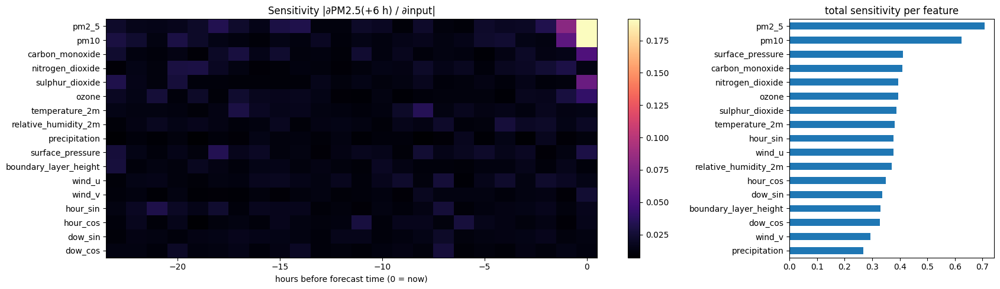


========== RESULTS FOR SLIDE 3 ==========
Theme / tier                             Live PM2.5 forecasting (real-time sample) / Hard path
Data                                     Open-Meteo live, Bengaluru, 27 Nov 2025 → 27 Nov 2026 21:00
RMSE @+6h persistence / ridge / NN       12.16 / 9.08 / 8.84 µg/m³
Skill @+6h (target 0.1)                  0.273  PASS
Regression @+6h m / c / R                0.63 / 8.3 / 0.840
AQI category accuracy @+6h               0.839
Hard path Delhi: trap skill              -0.509
Hard path Delhi: fixed skill             +0.227
Parameters / size (float32)              28454 / 111 KB
Latency per forecast (CPU)               0.13 ms


In [19]:
xt = tf.convert_to_tensor(Xte[:1000])
with tf.GradientTape() as tape:
    tape.watch(xt); out = model(xt)[:, -1]
G = np.abs(tape.gradient(out, xt).numpy()).mean(0).T            # (features, lags)
fig, ax = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw=dict(width_ratios=[3, 1]))
im = ax[0].imshow(G, aspect="auto", cmap="magma", extent=[-W + .5, .5, len(FEATURES) - .5, -.5])
ax[0].set_yticks(range(len(FEATURES))); ax[0].set_yticklabels(FEATURES); ax[0].set_xlabel("hours before forecast time (0 = now)")
ax[0].set_title(f"Sensitivity |∂PM2.5(+{H} h) / ∂input|"); fig.colorbar(im, ax=ax[0])
pd.Series(G.sum(1), FEATURES).sort_values().plot.barh(ax=ax[1]); ax[1].set_title("total sensitivity per feature")
plt.tight_layout(); plt.show()

t0 = time.time(); model.predict(Xte[:500], verbose=0); ms = (time.time() - t0) / 500 * 1000
print("\n========== RESULTS FOR SLIDE 3 ==========")
rows = [("Theme / tier", f"{CONFIG['theme']} / {CONFIG['tier']}"),
        ("Data", f"Open-Meteo live, {CONFIG['city']['name']}, {raw.index[0]:%d %b %Y} → {raw.index[-1]:%d %b %Y %H:00}"),
        (f"RMSE @+{H}h persistence / ridge / NN", f"{r_persist[-1]:.2f} / {r_ridge[-1]:.2f} / {r_nn[-1]:.2f} µg/m³"),
        (f"Skill @+{H}h (target {CONFIG['target_value']})", f"{skill[-1]:.3f}  {'PASS' if skill[-1] >= CONFIG['target_value'] else 'BELOW TARGET'}"),
        (f"Regression @+{H}h m / c / R", f"{m_:.2f} / {c_:.1f} / {R:.3f}"),
        (f"AQI category accuracy @+{H}h", f"{cat_acc:.3f}"),
        (f"Hard path {CONFIG['new_city']['name']}: trap skill", f"{sk(r2_trap, r2_persist):+.3f}"),
        (f"Hard path {CONFIG['new_city']['name']}: fixed skill", f"{sk(r2_fix, r2_persist):+.3f}"),
        ("Parameters / size (float32)", f"{model.count_params()} / {model.count_params()*4/1024:.0f} KB"),
        ("Latency per forecast (CPU)", f"{ms:.2f} ms")]
for a, b in rows: print(f"{a:<40} {b}")

## Step 13 — Live forecast from the latest data (+ a self-scoring log)
This is the **live proof** for your presentation, and it runs on data from the last hour:

1. Download the last 3 days of observations (up to the current hour), plus the official **CAMS** forecast for the next hours.
2. Build the latest 24-hour window, normalize it with the **training** statistics, and forecast +1 … +6 h.
3. Plot your forecast next to CAMS (a large physics-based model run by professionals; a hard benchmark).
4. **Append the forecast to `live_log.csv`.** Each time you re-run this cell later (in an hour, or tomorrow), it fills in the actual values for hours that have now happened, and it scores *your network vs CAMS vs persistence* on genuinely unseen future data.

This is the most honest test there is: the network cannot have seen the future, because it did not exist yet when the forecast was made.

The forecast uses whichever of the two trained models (absolute from Step 8, relative from Step 11) had the lower validation RMSE, averaged over all 6 horizons. The validation set picks the model; the test set is not used for this choice.

validation RMSE (mean of +1…+6 h): absolute 4.65 | relative 4.45 -> live model = relative


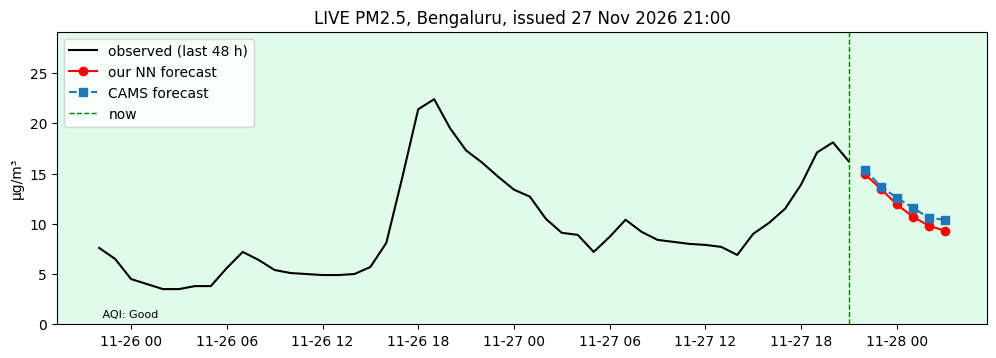

        target_time   nn aqi_nn  cams
2026-11-27 22:00:00 14.9   Good  15.4
2026-11-27 23:00:00 13.5   Good  13.7
2026-11-28 00:00:00 11.9   Good  12.6
2026-11-28 01:00:00 10.7   Good  11.6
2026-11-28 02:00:00  9.8   Good  10.6
2026-11-28 03:00:00  9.3   Good  10.4

Logged to live_log.csv. Re-run this cell after 22:00 to score this forecast against reality.


In [20]:
v_abs = rmse_by_h(Yva, model.predict(Xva, verbose=0)).mean()                     # mean over all 6 horizons
v_rel = rmse_by_h(Yva, from_relative(Xva, m_rel.predict(relative(Xva)[0], verbose=0))).mean()
USE_REL = v_rel < v_abs
print(f"validation RMSE (mean of +1…+{H} h): absolute {v_abs:.2f} | relative {v_rel:.2f} -> live model = {'relative' if USE_REL else 'absolute'}")

def forecast(X):
    return from_relative(X, m_rel.predict(relative(X)[0], verbose=0)) if USE_REL else model.predict(X, verbose=0)

def fetch_live(city, past_days=3):
    p = dict(latitude=city["lat"], longitude=city["lon"], timezone=CONFIG["timezone"], past_days=past_days, forecast_days=2)
    aq = get_hourly(AQ_URL, {**p, "hourly": ",".join(AQ_VARS)})
    wx = get_hourly(WX_LIVE_URL, {**p, "hourly": ",".join(WX_VARS)})
    return aq.join(wx, how="inner")

def live_step(city=CONFIG["city"], log_path="live_log.csv", show=True):
    now = now_local()
    df = fetch_live(city)
    past, future = df[df.index <= now], df[df.index > now]
    F = scale(make_features(past))[-W:]
    if np.isnan(F).any(): raise ValueError("latest window has gaps; try again later")
    pred = to_ugm3(forecast(F[None]))[0]
    t_fut = pd.date_range(past.index[-1] + pd.Timedelta(hours=1), periods=H, freq="h")
    cams = future.pm2_5.reindex(t_fut).to_numpy()
    out = pd.DataFrame({"issued": past.index[-1], "target_time": t_fut, "horizon_h": range(1, H + 1),
                        "nn": np.round(pred.astype(float), 1), "cams": cams, "persistence": past.pm2_5.iloc[-1], "city": city["name"]})
    out["aqi_nn"] = [AQI_NAMES[i] for i in aqi_cat(pred)]

    log = pd.read_csv(log_path, parse_dates=["issued", "target_time"]) if os.path.exists(log_path) else pd.DataFrame()
    log = pd.concat([log, out.drop(columns="aqi_nn")]).drop_duplicates(["city", "issued", "horizon_h"], keep="last")
    actual = past.pm2_5.rename("actual")
    log = log.drop(columns="actual", errors="ignore").merge(actual, left_on="target_time", right_index=True, how="left")
    log.to_csv(log_path, index=False)

    if show:
        hist48 = past.pm2_5.iloc[-48:]
        plt.figure(figsize=(12, 3.8))
        plt.plot(hist48.index, hist48, "k", label="observed (last 48 h)")
        plt.plot(t_fut, pred, "ro-", label="our NN forecast"); plt.plot(t_fut, cams, "s--", c="tab:blue", label="CAMS forecast")
        top = 1.3 * np.nanmax([hist48.max(), pred.max(), np.nanmax(cams) if np.isfinite(cams).any() else 0])
        for lo, hi, name, col in zip(AQI_BINS[:-1], AQI_BINS[1:], AQI_NAMES, ["#bbf7d0", "#d9f99d", "#fef08a", "#fed7aa", "#fecaca", "#e9d5ff"]):
            if lo < top: plt.axhspan(lo, min(hi, top), color=col, alpha=.45, lw=0); plt.text(hist48.index[0], lo + 0.5, f" AQI: {name}", fontsize=8, va="bottom")
        plt.ylim(0, top)
        plt.axvline(past.index[-1], c="g", ls="--", lw=1, label="now")
        plt.title(f"LIVE PM2.5, {city['name']}, issued {past.index[-1]:%d %b %Y %H:00}"); plt.ylabel("µg/m³"); plt.legend(); plt.show()
        print(out[["target_time", "nn", "aqi_nn", "cams"]].to_string(index=False, float_format="%.1f"))

    done = log.dropna(subset=["actual"])
    if len(done):
        print(f"\nSCORED LIVE FORECASTS ({len(done)} forecast-hours whose time has passed):")
        print(done.groupby("horizon_h").apply(lambda g: pd.Series({
            "n": len(g), "MAE_nn": (g.nn - g.actual).abs().mean(), "MAE_cams": (g.cams - g.actual).abs().mean(),
            "MAE_persist": (g.persistence - g.actual).abs().mean()})).round(2).to_string())
    else:
        print(f"\nLogged to {log_path}. Re-run this cell after {t_fut[0]:%H:00} to score this forecast against reality.")
    return out

live = live_step()

### Optional: keep it running (live monitor)
Set `UPDATES` > 1 to refresh every `EVERY_MIN` minutes. Each round fetches new data, forecasts, logs and re-scores. In Colab, leave the tab open. On a laptop, you could also save the model (`model.save("pm25.keras")`) and run `live_step()` from a cron job.

Keep `UPDATES = 1` for the submitted notebook so that *Run all* finishes quickly.

In [21]:
UPDATES, EVERY_MIN = 1, 60           # 1 = just the forecast already made above
for k in range(1, UPDATES):
    time.sleep(EVERY_MIN * 60)
    live_step()
model.save("pm25_model.keras"); json.dump({"mu": mu.to_dict(), "sd": sd.to_dict(), "features": FEATURES}, open("pm25_scaler.json", "w"))
print("saved pm25_model.keras + pm25_scaler.json")

saved pm25_model.keras + pm25_scaler.json


## Presentation checklist (3 minutes)
1. **Problem & tier (30 s)**: Step 1 table, target number, *"data is live up to today"*.
2. **Approach (60 s)**: time-delay network, time-ordered split, persistence baseline; what you changed and *why*.
3. **Result (60 s)**: the slide-3 table, the error-vs-horizon plot, and **one failure case** with your explanation (Step 10).
4. **Live proof (30 s)**: run Step 13 in front of the judges. Show today's forecast and the scored log from earlier runs.

### Ideas to go further
- Add the **weather forecast** for the next 6 hours as extra inputs (a NARX-style exogenous input). Rain and wind changes are the main failure cases.
- Several cities at once, with a city embedding. Or a 24–48 h horizon with an LSTM (`CONFIG["model"]="lstm"`).
- Swap in **real station data** from OpenAQ or CPCB and compare the results with the model data.

### Before you submit
- [ ] Runtime → *Restart and run all* finishes without errors in < 10 minutes
- [ ] Split is **by time**; scaler fitted on training data only; test set used once (Step 9 onwards)
- [ ] `data_cache/` from a successful run is included, so the notebook also works offline
- [ ] Every data source (Open-Meteo / CAMS), pretrained model and library is named on slide 2